# 6.1 Simple RNN network in PyTorch

In [13]:
import torch
import torch.nn as nn

class SimpleRNN(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1) # Output layer

    def forward(self, x, h0):
        out, hn = self.rnn(x, h0)
        out = self.fc(out[:, -1, :]) # Use the last time step's output
        return out, hn

# Hyperparameters
input_size = 10
hidden_size = 20
num_layers = 1
sequence_length = 5
batch_size = 3

# Create the model
model = SimpleRNN(input_size, hidden_size, num_layers)

# Example input sequence (batch_size, sequence_length, input_size)
input_seq = torch.randn(batch_size, sequence_length, input_size)

# Initial hidden state (num_layers, batch_size, hidden_size)
h0 = torch.zeros(num_layers, batch_size, hidden_size)

# Forward pass through the RNN
output, hn = model(input_seq, h0)
print("Input shape:", input_seq.shape)
print("Output shape:", output.shape)
print("Hidden state shape:", hn.shape)

# Example of using the model for a simple prediction task
x = torch.randn(1, sequence_length, input_size)  # Single sample
h0 = torch.zeros(num_layers, 1, hidden_size)
prediction, _ = model(x, h0)
print("Prediction:", prediction.item())

Input shape: torch.Size([3, 5, 10])
Output shape: torch.Size([3, 1])
Hidden state shape: torch.Size([1, 3, 20])
Prediction: -0.03337344154715538


# 6.2 LSTM in PyTorch

In [14]:
import torch
import torch.nn as nn

class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, (hn, cn) = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])
        return out, (hn, cn)

# Hyperparameters
input_size = 10
hidden_size = 20
num_layers = 2
output_size = 1
sequence_length = 5
batch_size = 3

# Create model instance
model = LSTMModel(input_size, hidden_size, num_layers, output_size)

# Example input sequence
input_seq = torch.randn(batch_size, sequence_length, input_size)

# Forward pass
output, (hn, cn) = model(input_seq)

# Print shapes
print("Input shape:", input_seq.shape)
print("Output shape:", output.shape)
print("Hidden state shape:", hn.shape)
print("Cell state shape:", cn.shape)

# Example of using the model for a simple prediction task
x = torch.randn(1, sequence_length, input_size)  # Single sample
prediction, _ = model(x)
print("Prediction:", prediction.item())

Input shape: torch.Size([3, 5, 10])
Output shape: torch.Size([3, 1])
Hidden state shape: torch.Size([2, 3, 20])
Cell state shape: torch.Size([2, 3, 20])
Prediction: -0.21008579432964325


# 6.3 GRU in PyTorch

In [15]:
import torch
import torch.nn as nn

class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.gru(x, h0)
        out = self.fc(out[:, -1, :])
        return out

# Hyperparameters
input_size = 10
hidden_size = 20
num_layers = 2
output_size = 1
sequence_length = 5
batch_size = 3

# Create model instance
model = GRUModel(input_size, hidden_size, num_layers, output_size)
# Example input sequence
input_seq = torch.randn(batch_size, sequence_length, input_size)
# Forward pass
output = model(input_seq)
# Print shapes
print("Input shape:", input_seq.shape)
print("Output shape:", output.shape)
# Example of using the model for a simple prediction task
x = torch.randn(1, sequence_length, input_size)  # Single sample
prediction = model(x)
print("Prediction:", prediction.item())

Input shape: torch.Size([3, 5, 10])
Output shape: torch.Size([3, 1])
Prediction: -0.5035024285316467


# 6.4 RNN in TensorFlow

In [16]:
import tensorflow as tf

# Define hyperparameters
batch_size = 32
sequence_length = 10
input_size = 8
hidden_units = 16
output_size = 4

# Create synthetic input data
input_data = tf.random.normal([batch_size, sequence_length, input_size])

# Define an RNN layer
rnn_layer = tf.keras.layers.SimpleRNN(units=hidden_units, return_sequences=True, return_state=True)

# Define a model using the Functional API
inputs = tf.keras.Input(shape=(sequence_length, input_size))
rnn_output, final_state = rnn_layer(inputs)
outputs = tf.keras.layers.Dense(output_size)(rnn_output)
model = tf.keras.Model(inputs=inputs, outputs=[outputs, final_state])

# Compile the model
model.compile(optimizer='adam', loss='mse')

# Generate synthetic target data
target_output = np.random.randn(batch_size, sequence_length, output_size)
target_final_state = np.random.randn(batch_size, hidden_units)

# Train the model
history = model.fit(
    input_data,
    [target_output, target_final_state],
    epochs=5,
    batch_size=batch_size
)

# Make predictions
predictions, final_state_pred = model.predict(input_data)

# Print shapes and sample outputs
print("Input Shape:", input_data.shape)
print("RNN Output Shape:", predictions.shape)
print("RNN Final State Shape:", final_state_pred.shape)
print("Sample Prediction (first sequence, first timestep):")
print(predictions[0, 0])
print("Sample Final State:")
print(final_state_pred[0])

Epoch 1/5


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 661ms/step - dense_22_loss: 1.5090 - loss: 2.8531 - simple_rnn_loss: 1.3441
Epoch 2/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - dense_22_loss: 1.4975 - loss: 2.8381 - simple_rnn_loss: 1.3406
Epoch 3/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - dense_22_loss: 1.4862 - loss: 2.8234 - simple_rnn_loss: 1.3371
Epoch 4/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - dense_22_loss: 1.4751 - loss: 2.8088 - simple_rnn_loss: 1.3337
Epoch 5/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - dense_22_loss: 1.4642 - loss: 2.7944 - simple_rnn_loss: 1.3302
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
Input Shape: (32, 10, 8)
RNN Output Shape: (32, 10, 4)
RNN Final State Shape: (32, 16)
Sample Prediction (first sequence, first timestep):
[ 0.37299836  0.34185258  0.22419599 -0.9504936 ]
Sample Final State:
[-0.08919212  0.00475892  0.12358305 -0.6444877   0.42629835  0.42411387
  0.43988606  0.23128179  0.83952117  0.6356713  -0.8761245   0.8615007
  0.837201   -0.12226519 -0.02915861  0.29963878]


# 6.5 LSTM in TensorFlow

In [17]:
import tensorflow as tf

# Define hyperparameters
batch_size = 32
sequence_length = 10
input_size = 8
hidden_units = 16
output_size = 4

# Create synthetic input data
input_data = tf.random.normal([batch_size, sequence_length, input_size])

# Define an LSTM layer
lstm_layer = tf.keras.layers.LSTM(units=hidden_units, return_sequences=True, return_state=True)

# Define a model using the Functional API
inputs = tf.keras.Input(shape=(sequence_length, input_size))
lstm_output, final_hidden_state, final_cell_state = lstm_layer(inputs)
outputs = tf.keras.layers.Dense(output_size)(lstm_output)
model = tf.keras.Model(inputs=inputs, outputs=[outputs, final_hidden_state, final_cell_state])

# Compile the model
model.compile(optimizer="adam", loss="mse")

# Generate synthetic target data
target_output = np.random.randn(batch_size, sequence_length, output_size)
target_hidden_state = np.random.randn(batch_size, hidden_units)
target_cell_state = np.random.randn(batch_size, hidden_units)

# Train the model
history = model.fit(
    input_data,
    [target_output, target_hidden_state, target_cell_state],
    batch_size=batch_size,
)

# Make predictions
predictions, final_hidden_state_pred, final_cell_state_pred = model.predict(input_data)

# Print shapes and sample outputs
print("Input Shape:", input_data.shape)
print("LSTM Output Shape:", predictions.shape)
print("LSTM Final Hidden State Shape:", final_hidden_state_pred.shape)
print("LSTM Final Cell State Shape:", final_cell_state_pred.shape)
print("Sample Prediction (first sequence, first timestep):")
print(predictions[0, 0])
print("Sample Final Hidden State:")
print(final_hidden_state_pred[0])
print("Sample Final Cell State:")
print(final_cell_state_pred[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 705ms/step - dense_23_loss: 0.9346 - loss: 3.0965 - lstm_5_loss: 1.2264
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
Input Shape: (32, 10, 8)
LSTM Output Shape: (32, 10, 4)
LSTM Final Hidden State Shape: (32, 16)
LSTM Final Cell State Shape: (32, 16)
Sample Prediction (first sequence, first timestep):
[-0.1582183  -0.09059728  0.10706476 -0.03265964]
Sample Final Hidden State:
[ 0.0333346   0.05492363 -0.2390742   0.01196652 -0.10634084 -0.0958845
  0.02031216 -0.12651202  0.10725971  0.04807237 -0.08193211 -0.05156986
 -0.01430639 -0.09130297  0.37447172  0.07669996]
Sample Final Cell State:
[ 0.07294637  0.09097965 -0.45706883  0.02658822 -0.25277218 -0.21739106
  0.04682783 -0.19882117  0.2657262   0.09238552 -0.20195843 -0.10092843
 -0.02903224 -0.1621896   0.722703    0.1815405 ]


# 6.6 RNN in Keras

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 417 (1.63 KB)

 Trainable params: 417 (1.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4925 - loss: 0.7721 - val_accuracy: 0.5400 - val_loss: 0.7352
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5088 - loss: 0.7440 - val_accuracy: 0.5350 - val_loss: 0.7236
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5150 - loss: 0.7249 - val_accuracy: 0.5200 - val_loss: 0.7179
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5288 - loss: 0.7098 - val_accuracy: 0.5150 - val_loss: 0.7158
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5450 - loss: 0.6994 - val_accuracy: 0.5250 - val_loss: 0.7144
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5562 - loss: 0.6914 - val_accuracy: 0.5350 - val_loss: 0.7139
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5638 - loss: 0.6857 - val_accuracy: 0.5400 - val_loss: 0.7149
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5750 - loss: 0.6802 - val_accuracy: 0.5400 - val_loss:

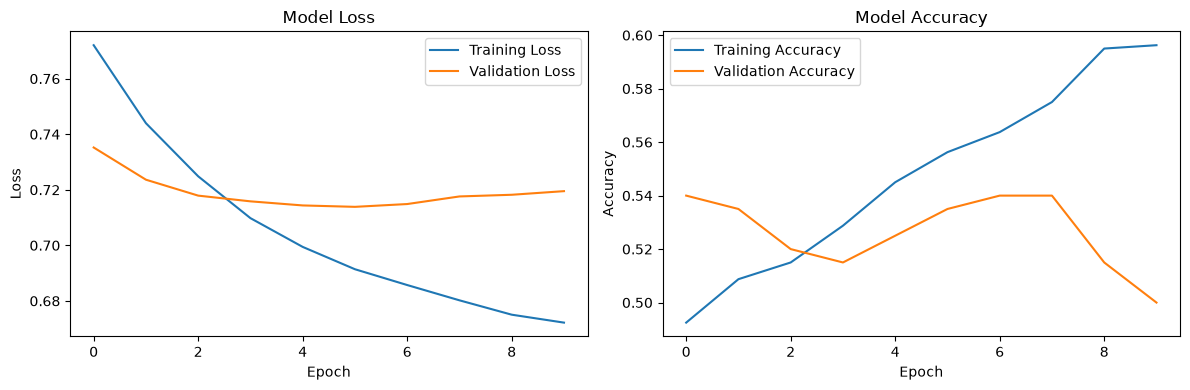

In [18]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Input
import numpy as np
import matplotlib.pyplot as plt

# Define hyperparameters
sequence_length = 10
input_features = 8
hidden_units = 16
output_size = 1
batch_size = 32
epochs = 10

# Generate synthetic data
X = np.random.randn(1000, sequence_length, input_features)
y = np.random.randint(0, 2, (1000, 1)) # Binary classification

# Define a sequential model
model = Sequential([
    Input(shape=(sequence_length, input_features)),
    SimpleRNN(units=hidden_units, return_sequences=False),
    Dense(units=output_size, activation='sigmoid')
])

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
# Print the model summary
model.summary()
# Train the model
history = model.fit(X, y, batch_size=batch_size, epochs=epochs, validation_split=0.2)
# Evaluate the model
test_loss, test_accuracy = model.evaluate(X, y)
print(f"Test accuracy: {test_accuracy:.4f}")
# Make predictions
sample_input = np.random.randn(1, sequence_length, input_features)
prediction = model.predict(sample_input)
print(f"Sample prediction: {prediction[0][0]:.4f}")
# Plot training history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# 6.7 LSTM in Keras

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 16)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,617 (6.32 KB)

 Trainable params: 1,617 (6.32 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5088 - loss: 0.7001 - val_accuracy: 0.4300 - val_loss: 0.7101
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5238 - loss: 0.6942 - val_accuracy: 0.4450 - val_loss: 0.7101
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5375 - loss: 0.6905 - val_accuracy: 0.4350 - val_loss: 0.7116
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5400 - loss: 0.6879 - val_accuracy: 0.4600 - val_loss: 0.7130
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5537 - loss: 0.6852 - val_accuracy: 0.4600 - val_loss: 0.7138
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5650 - loss: 0.6831 - val_accuracy: 0.4850 - val_loss: 0.7158
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5713 - loss: 0.6809 - val_accuracy: 0.5000 - val_loss: 0.7180
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5738 - loss: 0.6792 - val_accuracy: 0.4900 - val_loss:

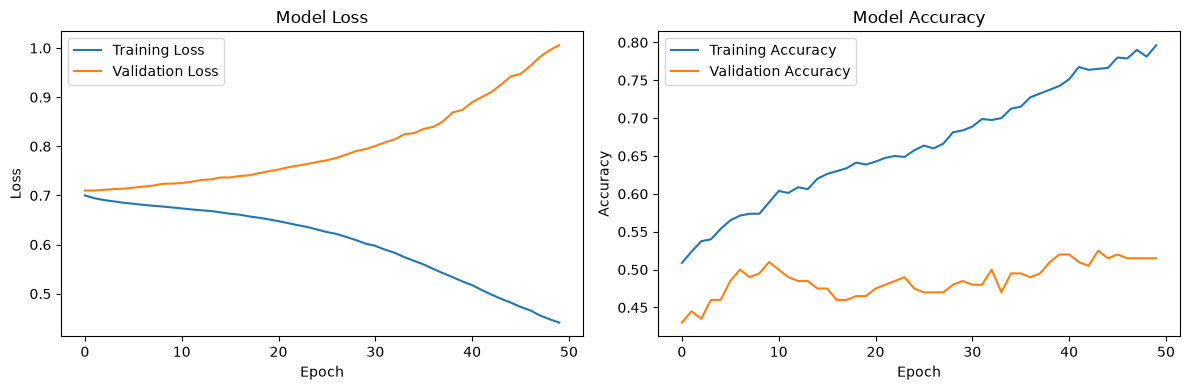

In [19]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
import numpy as np
import matplotlib.pyplot as plt

# Define hyperparameters
sequence_length = 10
input_features = 8
hidden_units = 16
output_size = 1
batch_size = 32
epochs = 50

# Generate synthetic data
X = np.random.randn(1000, sequence_length, input_features)
y = np.random.randint(0, 2, (1000, 1)) # Binary classification

# Define a sequential model
model = Sequential([
    Input(shape=(sequence_length, input_features)), 
    LSTM(units=hidden_units, return_sequences=False),
    Dense(units=output_size, activation='sigmoid')
])
# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
# Print the model summary
model.summary()
# Train the model
history = model.fit(X, y, batch_size=batch_size, epochs=epochs, validation_split=0.2)
# Evaluate the model
test_loss, test_accuracy = model.evaluate(X, y)
print(f"Test accuracy: {test_accuracy:.4f}")
# Make predictions
sample_input = np.random.randn(1, sequence_length, input_features)
prediction = model.predict(sample_input)
print(f"Sample prediction: {prediction[0][0]:.4f}")
# Plot training history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

# 6.8 RNN in PyTorch

Epoch [10/100], Train Loss: 0.6756, Test Loss: 0.7054, Test Accuracy: 51.00%
Epoch [20/100], Train Loss: 0.6330, Test Loss: 0.7599, Test Accuracy: 52.00%
Epoch [30/100], Train Loss: 0.5936, Test Loss: 0.7943, Test Accuracy: 59.00%
Epoch [40/100], Train Loss: 0.5451, Test Loss: 0.8292, Test Accuracy: 53.00%
Epoch [50/100], Train Loss: 0.4762, Test Loss: 0.8855, Test Accuracy: 50.00%
Epoch [60/100], Train Loss: 0.4181, Test Loss: 1.0155, Test Accuracy: 47.00%
Epoch [70/100], Train Loss: 0.3376, Test Loss: 1.1079, Test Accuracy: 53.00%
Epoch [80/100], Train Loss: 0.2819, Test Loss: 1.2492, Test Accuracy: 56.00%
Epoch [90/100], Train Loss: 0.2207, Test Loss: 1.3991, Test Accuracy: 54.00%
Epoch [100/100], Train Loss: 0.1510, Test Loss: 1.5257, Test Accuracy: 51.00%


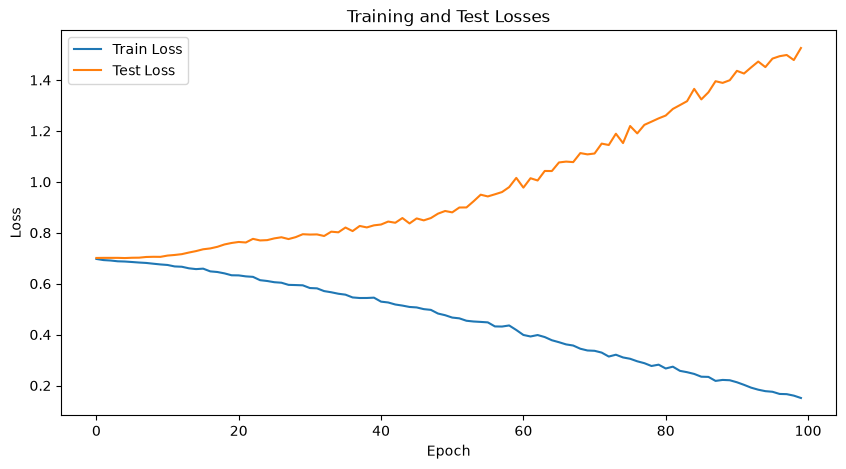

Prediction for new data: 0.0200


In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Define an RNN-based model
class RNNModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, num_layers=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h0 = x.new_zeros(self.num_layers, x.size(0), self.hidden_size)
        out, _ = self.rnn(x, h0)
        return self.fc(out[:, -1, :])

# Set random seed for reproducibility
torch.manual_seed(42)
# Hyperparameters
input_size = 8
hidden_size = 16
output_size = 1
num_layers = 2
batch_size = 32
sequence_length = 10
num_epochs = 100
learning_rate = 0.001
# Generate synthetic data
X = torch.randn(500, sequence_length, input_size)
y = torch.randint(0, 2, (500, 1)).float()
# Split data into train and test sets
train_size = int(0.8 * len(X))
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]
# Create data loaders
train_dataset = torch.utils.data.TensorDataset(X_train, y_train)
test_dataset = torch.utils.data.TensorDataset(X_test, y_test)
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True
)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size)
# Initialize model, loss function, and optimizer
model = RNNModel(input_size, hidden_size, output_size, num_layers)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
# Training loop
train_losses = []
test_losses = []
for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            outputs = model(inputs)
            test_loss += criterion(outputs, labels).item()
            predicted = outputs >= 0
            correct += (predicted == labels.bool()).sum().item()
            total += labels.size(0)

    test_loss /= len(test_loader)
    test_losses.append(test_loss)
    accuracy = 100 * correct / total
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{num_epochs}], "
            f"Train Loss: {train_loss:.4f}, "
            f"Test Loss: {test_loss:.4f}, "
            f"Test Accuracy: {accuracy:.2f}%"
        )

# Plot training and test losses
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Test Losses")
plt.legend()
plt.show()
# Make predictions on new data
new_data = torch.randn(1, sequence_length, input_size)
model.eval()
with torch.no_grad():
    prediction = torch.sigmoid(model(new_data))
    print(f"Prediction for new data: {prediction.item():.4f}")

# 6.9 LSTM in PyTorch

Epoch [10/100], Train Loss: 0.6881, Test Loss: 0.6954, Test Accuracy: 40.00%
Epoch [20/100], Train Loss: 0.6676, Test Loss: 0.7276, Test Accuracy: 50.00%
Epoch [30/100], Train Loss: 0.6348, Test Loss: 0.7167, Test Accuracy: 52.00%
Epoch [40/100], Train Loss: 0.5595, Test Loss: 0.7606, Test Accuracy: 52.00%
Epoch [50/100], Train Loss: 0.4158, Test Loss: 0.8026, Test Accuracy: 56.00%
Epoch [60/100], Train Loss: 0.3422, Test Loss: 0.9574, Test Accuracy: 54.00%
Epoch [70/100], Train Loss: 0.2361, Test Loss: 1.0958, Test Accuracy: 59.00%
Epoch [80/100], Train Loss: 0.2613, Test Loss: 1.3564, Test Accuracy: 53.00%
Epoch [90/100], Train Loss: 0.1466, Test Loss: 1.6451, Test Accuracy: 53.00%
Epoch [100/100], Train Loss: 0.1072, Test Loss: 1.6959, Test Accuracy: 55.00%


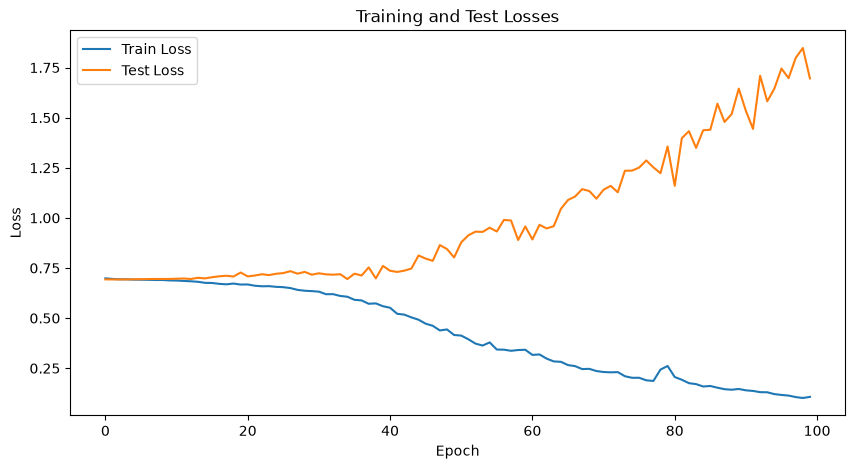

Prediction for new data: 0.7796


In [21]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Define an LSTM-based model
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, num_layers=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h0 = x.new_zeros(self.num_layers, x.size(0), self.hidden_size)
        c0 = x.new_zeros(self.num_layers, x.size(0), self.hidden_size)
        out, _ = self.lstm(x, (h0, c0))
        return self.fc(out[:, -1, :])

# Set random seed for reproducibility
torch.manual_seed(42)

# Hyperparameters
input_size = 8
hidden_size = 16
output_size = 1
num_layers = 2
batch_size = 32
sequence_length = 10
num_epochs = 100
learning_rate = 0.001

# Generate synthetic data
X = torch.randn(500, sequence_length, input_size)
y = torch.randint(0, 2, (500, 1)).float()

# Split data into train and test sets
train_size = int(0.8 * len(X))
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Create data loaders
train_dataset = torch.utils.data.TensorDataset(X_train, y_train)
test_dataset = torch.utils.data.TensorDataset(X_test, y_test)
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True
)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size)

# Initialize model, loss function, and optimizer
model = LSTMModel(input_size, hidden_size, output_size, num_layers)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Training loop
train_losses = []
test_losses = []
for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            outputs = model(inputs)
            test_loss += criterion(outputs, labels).item()
            predicted = outputs >= 0
            correct += (predicted == labels.bool()).sum().item()
            total += labels.size(0)

    test_loss /= len(test_loader)
    test_losses.append(test_loss)
    accuracy = 100 * correct / total
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{num_epochs}], "
            f"Train Loss: {train_loss:.4f}, "
            f"Test Loss: {test_loss:.4f}, "
            f"Test Accuracy: {accuracy:.2f}%"
        )

# Plot training and test losses
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Test Losses")
plt.legend()
plt.show()
# Make predictions on new data
new_data = torch.randn(1, sequence_length, input_size)
model.eval()
with torch.no_grad():
    prediction = torch.sigmoid(model(new_data))
    print(f"Prediction for new data: {prediction.item():.4f}")

# 6.10 Language modeling with RNNs in PyTorch

Epoch [1/10], Batch [1/157], Loss: 8.5583
Epoch [1/10], Batch [101/157], Loss: 8.5488
Epoch [1/10], Average Loss: 8.5696
Epoch [2/10], Batch [1/157], Loss: 8.5122
Epoch [2/10], Batch [101/157], Loss: 8.5136
Epoch [2/10], Average Loss: 8.5184
Epoch [3/10], Batch [1/157], Loss: 8.4656
Epoch [3/10], Batch [101/157], Loss: 8.4881
Epoch [3/10], Average Loss: 8.4767
Epoch [4/10], Batch [1/157], Loss: 8.4049
Epoch [4/10], Batch [101/157], Loss: 8.4330
Epoch [4/10], Average Loss: 8.4318
Epoch [5/10], Batch [1/157], Loss: 8.3428
Epoch [5/10], Batch [101/157], Loss: 8.4044
Epoch [5/10], Average Loss: 8.3796
Epoch [6/10], Batch [1/157], Loss: 8.3167
Epoch [6/10], Batch [101/157], Loss: 8.3481
Epoch [6/10], Average Loss: 8.3328
Epoch [7/10], Batch [1/157], Loss: 8.1991
Epoch [7/10], Batch [101/157], Loss: 8.3167
Epoch [7/10], Average Loss: 8.2852
Epoch [8/10], Batch [1/157], Loss: 8.1872
Epoch [8/10], Batch [101/157], Loss: 8.3087
Epoch [8/10], Average Loss: 8.2437
Epoch [9/10], Batch [1/157], Los

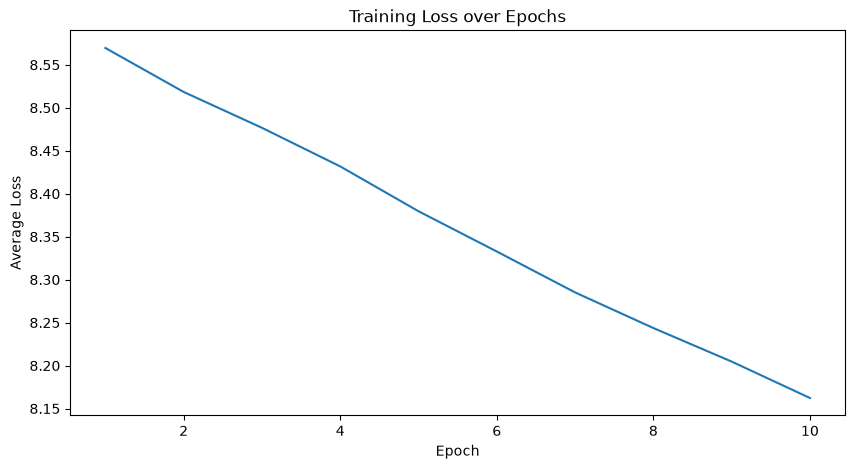

Generated sequence: [np.int64(3748), np.int64(3753), np.int64(1184), np.int64(3092), np.int64(3297), np.int64(2677), np.int64(3217), np.int64(1509), np.int64(97), np.int64(3715), np.int64(502), np.int64(4026), np.int64(4462), np.int64(342), np.int64(3745), np.int64(2134), np.int64(2822), np.int64(2030), np.int64(4802), np.int64(952), 2096, 4208, 1916, 1776, 4081, 3484, 1467, 3232, 938, 4105, 3311, 2391, 3637, 4748, 979, 35, 3418, 3135, 4506, 442, 2752, 1907, 3213, 4293, 4770, 165, 4956, 96, 222, 1629, 3004, 630, 860, 717, 92, 1665, 509, 1550, 2907, 3854, 4212, 4822, 1823, 47, 4421, 3614, 2814, 2407, 1690, 1144]
Output shape: torch.Size([32, 20, 5000])
Hidden state shape: torch.Size([2, 32, 256])


In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt

# Define the RNN-based language model
class RNNLanguageModel(nn.Module):
    def __init__(self, vocab_size, embed_size, hidden_size, num_layers, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.rnn = nn.RNN(
            embed_size,
            hidden_size,
            num_layers,
            batch_first=True,
            dropout=dropout,
        )
        self.fc = nn.Linear(hidden_size, vocab_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, hidden):
        x = self.embedding(x)
        x = self.dropout(x)
        out, hidden = self.rnn(x, hidden)
        out = self.dropout(out)
        out = self.fc(out)
        return out, hidden

    def init_hidden(self, batch_size):
        weight = next(self.parameters()).data
        return weight.new(
            self.rnn.num_layers, batch_size, self.rnn.hidden_size
        ).zero_()

# Custom dataset for language modeling
class LanguageModelDataset(Dataset):
    def __init__(self, text, seq_length):
        self.text = text
        self.seq_length = seq_length
        self.total_seq = (len(self.text) - 1) // self.seq_length

    def __len__(self):
        return self.total_seq

    def __getitem__(self, idx):
        start_idx = idx * self.seq_length
        end_idx = start_idx + self.seq_length
        sequence = self.text[start_idx:end_idx]
        target = self.text[start_idx + 1 : end_idx + 1]
        return torch.LongTensor(sequence), torch.LongTensor(target)

# Function to generate text
def generate_text(model, start_seq, vocab_size, temperature=1.0, generated_seq_len=50):
    model.eval()
    current_seq = start_seq
    generated_text = list(current_seq)
    hidden = model.init_hidden(1)

    with torch.no_grad():
        for _ in range(generated_seq_len):
            input_seq = torch.LongTensor(current_seq).unsqueeze(0)
            output, hidden = model(input_seq, hidden)
            output = output[:, -1, :] / temperature
            probs = torch.softmax(output, dim=-1)
            next_word = torch.multinomial(probs, 1).item()
            generated_text.append(next_word)
            current_seq = current_seq[1:] + [next_word]

    return generated_text

# Hyperparameters
vocab_size = 5000
embed_size = 128
hidden_size = 256
num_layers = 2
dropout = 0.5
batch_size = 32
seq_length = 20
num_epochs = 10
learning_rate = 0.001

# Generate synthetic data
text_length = 100000
synthetic_text = np.random.randint(0, vocab_size, text_length)

# Create dataset and dataloader
dataset = LanguageModelDataset(synthetic_text, seq_length)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Initialize the language model
model = RNNLanguageModel(vocab_size, embed_size, hidden_size, num_layers, dropout)
# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Training loop
losses = []
for epoch in range(num_epochs):
    model.train()
    total_loss = 0

    for batch, (inputs, targets) in enumerate(dataloader):
        hidden = model.init_hidden(inputs.size(0))
        optimizer.zero_grad()
        output, hidden = model(inputs, hidden)
        loss = criterion(output.transpose(1, 2), targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

        if batch % 100 == 0:
            print(
                f"Epoch [{epoch + 1}/{num_epochs}], "
                f"Batch [{batch + 1}/{len(dataloader)}], "
                f"Loss: {loss.item():.4f}"
            )

    avg_loss = total_loss / len(dataloader)
    losses.append(avg_loss)
    print(f"Epoch [{epoch + 1}/{num_epochs}], Average Loss: {avg_loss:.4f}")

# Plot the training loss
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), losses)
plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.title("Training Loss over Epochs")
plt.show()

# Generate some text
start_sequence = list(np.random.randint(0, vocab_size, seq_length))
generated_sequence = generate_text(model, start_sequence, vocab_size)
print("Generated sequence:", generated_sequence)

# Example input for a forward pass
input_seq = torch.randint(0, vocab_size, (batch_size, seq_length))
hidden = model.init_hidden(batch_size)
output, hidden = model(input_seq, hidden)
print("Output shape:", output.shape)
print("Hidden state shape:", hidden.shape)

# 6.11 Character-level text generation using LSTM in TensorFlow

In [23]:
import tensorflow as tf
import numpy as np

# Create a character-level vocabulary
vocabulary = "abcdefghijklmnopqrstuvwxyz "
char2idx = {char: index for index, char in enumerate(vocabulary)}
idx2char = {index: char for char, index in char2idx.items()}
vocab_size = len(vocabulary)

# Define a simple LSTM-based character-level text generation model
class LSTMTextGenerator(tf.keras.Model):
    def __init__(self, vocab_size, embed_size, lstm_units):
        super().__init__()
        self.embedding = tf.keras.layers.Embedding(vocab_size, embed_size)
        self.lstm = tf.keras.layers.LSTM(
            lstm_units, return_sequences=True, return_state=True
        )
        self.fc = tf.keras.layers.Dense(vocab_size)

    def call(self, inputs, states=None):
        x = self.embedding(inputs)
        output, state_h, state_c = self.lstm(x, initial_state=states)
        logits = self.fc(output)
        return logits, [state_h, state_c]

    def generate_text(self, start_string, num_generate, temperature=1.0):
        if temperature <= 0:
            raise ValueError("temperature must be greater than 0")

        input_eval = tf.expand_dims([char2idx[char] for char in start_string], 0)
        text_generated = []
        states = None

        for _ in range(num_generate):
            logits, states = self(input_eval, states)
            logits = logits[:, -1, :] / temperature
            predicted_id = tf.random.categorical(logits, num_samples=1)[0, 0].numpy()
            text_generated.append(idx2char[predicted_id])
            input_eval = tf.expand_dims([predicted_id], 0)

        return start_string + "".join(text_generated)

# Hyperparameters and model initialization
embed_size = 64
lstm_units = 128
model = LSTMTextGenerator(vocab_size, embed_size, lstm_units)

# Run a forward pass with a batch of example inputs
input_seq = tf.random.uniform(
    (32, 50), minval=0, maxval=vocab_size, dtype=tf.int32
)
initial_state = [
    tf.zeros((32, lstm_units)),
    tf.zeros((32, lstm_units)),
]
output, states = model(input_seq, initial_state)
print("Output shape:", output.shape)

# Generate example text
generated_text = model.generate_text("hello", num_generate=50, temperature=0.7)
print("Generated text:", generated_text)

# Define the training step
optimizer = tf.keras.optimizers.Adam()

def train_step(input_seq, target_seq):
    with tf.GradientTape() as tape:
        logits, _ = model(input_seq)
        loss = tf.keras.losses.sparse_categorical_crossentropy(
            target_seq, logits, from_logits=True
        )
        loss = tf.reduce_mean(loss)

    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    return loss

# Create next-character training examples from a larger sample corpus
training_text = (
    "the curious fox walks through the quiet forest and watches birds fly above the trees "
    "a small robot learns to read maps and finds a new path beside the river "
    "bright stars appear in the evening sky while the moon rises over the hills "
    "people share stories grow food build homes and help their neighbors "
    "gentle rain fills the garden and green leaves open in the warm morning sun "
    "the patient explorer follows winding roads across valleys fields and mountains "
    "children build a wooden boat and sail across the lake on a calm summer day "
    "a baker mixes flour water and yeast before placing fresh bread in the oven "
    "the train travels between busy cities carrying families books and supplies "
    "deep in the ocean bright fish move between coral reefs and swaying sea plants "
    "the old library keeps maps poems and curious tales from many distant places "
    "workers plant young trees along the road to create shade for future travelers "
    "a gentle dog follows its friend through fields of clover and golden grass "
    "scientists watch tiny cells grow and record how they change over time "
    "in winter the river slows as frost covers the stones along its banks "
    "a careful cook adds herbs beans and vegetables to a large warm pot "
    "the village market opens early with apples carrots flowers and fresh cheese "
    "wind moves across the plain and turns the blades of a tall water wheel "
    "a young musician practices each evening and learns a new melody on the piano "
    "the mountain path leads past clear springs quiet forests and open meadows "
    "after the storm the clouds move away and sunlight returns to the rooftops "
    "friends explore the old castle and imagine how people lived there long ago "
    "a family gathers around the table to enjoy soup and talk about the day "
    "the morning bus stops near the school where students carry notebooks and lunch "
    "when the leaves turn gold the forest becomes bright with color and birdsong "
) * 40
text_as_int = [char2idx[char] for char in training_text]
sequence_length = 50
sequences = tf.data.Dataset.from_tensor_slices(text_as_int).batch(
    sequence_length + 1, drop_remainder=True
)

def split_input_target(sequence):
    return sequence[:-1], sequence[1:]

dataset = (
    sequences.map(split_input_target)
    .shuffle(1000)
    .batch(32, drop_remainder=True)
)

epochs = 20
for epoch in range(epochs):
    total_loss = 0.0
    num_batches = 0

    for input_seq, target_seq in dataset:
        loss = train_step(input_seq, target_seq)
        total_loss += loss.numpy()
        num_batches += 1

    average_loss = total_loss / num_batches
    print(f"Epoch {epoch + 1}, Loss: {average_loss:.4f}")

# Generate text after training
final_generated_text = model.generate_text(
    "hello world", num_generate=100, temperature=0.7
)
print("Final generated text:", final_generated_text)

Output shape: (32, 50, 27)
Generated text: hellonblcnzlxrsqscduybakeecgmjkghxegkyrilzlvhdqowdcgnzx
Epoch 1, Loss: 2.9196
Epoch 2, Loss: 2.4556
Epoch 3, Loss: 2.1429
Epoch 4, Loss: 1.9794
Epoch 5, Loss: 1.8245
Epoch 6, Loss: 1.6583
Epoch 7, Loss: 1.4758
Epoch 8, Loss: 1.2902
Epoch 9, Loss: 1.1160
Epoch 10, Loss: 0.9585
Epoch 11, Loss: 0.8243
Epoch 12, Loss: 0.7052
Epoch 13, Loss: 0.6074
Epoch 14, Loss: 0.5255
Epoch 15, Loss: 0.4616
Epoch 16, Loss: 0.4100
Epoch 17, Loss: 0.3690
Epoch 18, Loss: 0.3367
Epoch 19, Loss: 0.3109
Epoch 20, Loss: 0.2894
Final generated text: hello world ture the old wactres carren folle sw about the tare an a calks frees bardy move away and sunlight r


# 6.12 Sentiment analysis using GRU in Keras

In [24]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Embedding
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Example dataset: list of sentences with sentiment labels
sentences = [
    "I love this movie!",
    "This movie was terrible...",
    "I really enjoyed the performance.",
    "The acting was mediocre at best.",
    "A masterpiece of modern cinema!",
    "I wouldn't recommend this film to anyone.",
    "An average movie, nothing special.",
    "The plot was confusing and hard to follow.",
    "A delightful experience from start to finish!",
    "The special effects were impressive, but the story was lacking.",
]
labels = np.array([1, 0, 1, 0, 1, 0, 2, 0, 1, 2])
class_names = {0: "negative", 1: "positive", 2: "neutral"}
# Tokenize and pad the sequences
max_words = 10000
max_len = 20
tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(sentences)
sequences = tokenizer.texts_to_sequences(sentences)
padded_sequences = pad_sequences(sequences, maxlen=max_len)
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    padded_sequences, labels, test_size=0.2, random_state=42
)
# Define a GRU-based sentiment analysis model
model = Sequential(
    [
        Embedding(input_dim=max_words, output_dim=64),
        GRU(units=64, return_sequences=True),
        GRU(units=32),
        Dense(16, activation="relu"),
        Dense(3, activation="softmax"),
    ]
)
# Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
# Define early stopping
early_stopping = EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)
# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=2,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1,
)
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {accuracy:.4f}")
# Make predictions
y_pred = model.predict(X_test, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)
# Print classification report
print(
    classification_report(
        y_test,
        y_pred_classes,
        labels=[0, 1, 2],
        target_names=[class_names[index] for index in range(3)],
        zero_division=0,
    )
)
# Function to predict sentiment for new sentences
def predict_sentiment(sentences):
    sequences = tokenizer.texts_to_sequences(sentences)
    padded = pad_sequences(sequences, maxlen=max_len)
    predictions = model.predict(padded, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)
    return [class_names[class_id] for class_id in predicted_classes]
# Example usage
new_sentences = [
    "This movie exceeded all my expectations!",
    "I fell asleep halfway through the film.",
    "It was okay, but nothing to write home about.",
]
sentiments = predict_sentiment(new_sentences)
for sentence, sentiment in zip(new_sentences, sentiments):
    print(f"Sentence: {sentence}")
    print(f"Sentiment: {sentiment}")
    print()

Epoch 1/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 116ms/step - accuracy: 0.1667 - loss: 1.1004 - val_accuracy: 0.0000e+00 - val_loss: 1.0986
Epoch 2/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - loss: 1.0824 - val_accuracy: 0.0000e+00 - val_loss: 1.1006
Epoch 3/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 1.0000 - loss: 1.0672 - val_accuracy: 0.5000 - val_loss: 1.1046
Epoch 4/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 1.0000 - loss: 1.0462 - val_accuracy: 0.5000 - val_loss: 1.1123
Test accuracy: 0.5000
              precision    recall  f1-score   support

    negative       0.50      1.00      0.67         1
    positive       0.00      0.00      0.00         1
     neutral       0.00      0.00      0.00         0

    accuracy                           0.50         2
   macro avg       0.17      0.33      0.22         2
weighted avg       0.25      0.50      0.33         2

Sentence: This movie exceeded all my expectations!
Sentiment: negative

Sentence: I fell

# 6.13 Self-attention mechanism in TensorFlow

In [25]:
import tensorflow as tf

# Define the scaled dot-product attention
def scaled_dot_product_attention(query, key, value, mask=None):
    """Calculate attention weights and the weighted sum of values."""
    matmul_qk = tf.matmul(query, key, transpose_b=True)
    depth = tf.cast(tf.shape(key)[-1], tf.float32)
    scaled_attention_logits = matmul_qk / tf.math.sqrt(depth)

    if mask is not None:
        scaled_attention_logits += mask * -1e9

    attention_weights = tf.nn.softmax(scaled_attention_logits, axis=-1)
    output = tf.matmul(attention_weights, value)
    return output, attention_weights


class MultiHeadAttention(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads):
        super().__init__()
        if d_model % num_heads != 0:
            raise ValueError("d_model must be divisible by num_heads")

        self.num_heads = num_heads
        self.d_model = d_model
        self.depth = d_model // num_heads
        self.wq = tf.keras.layers.Dense(d_model)
        self.wk = tf.keras.layers.Dense(d_model)
        self.wv = tf.keras.layers.Dense(d_model)
        self.dense = tf.keras.layers.Dense(d_model)

    def split_heads(self, x, batch_size):
        """Split the last dimension into heads and transpose for attention."""
        x = tf.reshape(x, (batch_size, -1, self.num_heads, self.depth))
        return tf.transpose(x, perm=[0, 2, 1, 3])

    def call(self, v, k, q, mask=None):
        batch_size = tf.shape(q)[0]
        q = self.split_heads(self.wq(q), batch_size)
        k = self.split_heads(self.wk(k), batch_size)
        v = self.split_heads(self.wv(v), batch_size)

        scaled_attention, attention_weights = scaled_dot_product_attention(
            q, k, v, mask
        )
        scaled_attention = tf.transpose(scaled_attention, perm=[0, 2, 1, 3])
        concat_attention = tf.reshape(
            scaled_attention, (batch_size, -1, self.d_model)
        )
        output = self.dense(concat_attention)
        return output, attention_weights


# Example usage
d_model = 512
num_heads = 8
mha = MultiHeadAttention(d_model, num_heads)

# Example inputs (batch_size=1, sequence_length=60, d_model=512)
query = tf.random.normal(shape=(1, 60, d_model))
key = value = query
output, attention_weights = mha(value, key, query)
print("Multi-Head Attention Output shape:", output.shape)
print("Attention Weights shape:", attention_weights.shape)


Multi-Head Attention Output shape: (1, 60, 512)
Attention Weights shape: (1, 8, 60, 60)


# 6.14 Transformer block in TensorFlow

In [26]:
import tensorflow as tf
import numpy as np

def positional_encoding(position, d_model):
    def get_angles(pos, i, d_model):
        angle_rates = 1 / np.power(
            10000, (2 * (i // 2)) / np.float32(d_model)
        )
        return pos * angle_rates

    angle_rads = get_angles(
        np.arange(position)[:, np.newaxis],
        np.arange(d_model)[np.newaxis, :],
        d_model,
    )
    angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
    angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
    pos_encoding = angle_rads[np.newaxis, ...]
    return tf.cast(pos_encoding, dtype=tf.float32)


class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super().__init__()
        if embed_dim % num_heads != 0:
            raise ValueError("embed_dim must be divisible by num_heads")
        self.attention = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim // num_heads
        )
        self.ffn = tf.keras.Sequential(
            [
                tf.keras.layers.Dense(ff_dim, activation="relu"),
                tf.keras.layers.Dense(embed_dim),
            ]
        )
        self.layernorm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = tf.keras.layers.Dropout(rate)
        self.dropout2 = tf.keras.layers.Dropout(rate)

    def call(self, inputs, training=None):
        attn_output = self.attention(inputs, inputs)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)


class TransformerModel(tf.keras.Model):
    def __init__(
        self,
        num_layers,
        embed_dim,
        num_heads,
        ff_dim,
        input_vocab_size,
        target_vocab_size,
        max_seq_length,
    ):
        super().__init__()
        self.embedding = tf.keras.layers.Embedding(input_vocab_size, embed_dim)
        self.pos_encoding = positional_encoding(max_seq_length, embed_dim)
        self.transformer_blocks = [
            TransformerBlock(embed_dim, num_heads, ff_dim)
            for _ in range(num_layers)
        ]
        self.dropout = tf.keras.layers.Dropout(0.1)
        self.final_layer = tf.keras.layers.Dense(target_vocab_size)

    def call(self, inputs, training=None):
        x = self.embedding(inputs)
        x *= tf.math.sqrt(tf.cast(self.embedding.output_dim, tf.float32))
        x += self.pos_encoding[:, : tf.shape(inputs)[1], :]
        x = self.dropout(x, training=training)
        for transformer_block in self.transformer_blocks:
            x = transformer_block(x, training=training)
        return self.final_layer(x)


# Example usage
embed_dim = 64
num_heads = 8
ff_dim = 128
num_layers = 4
input_vocab_size = 5000
target_vocab_size = 5000
max_seq_length = 100
model = TransformerModel(
    num_layers,
    embed_dim,
    num_heads,
    ff_dim,
    input_vocab_size,
    target_vocab_size,
    max_seq_length,
)

# Example input (batch_size=32, sequence_length=10)
inputs = tf.random.uniform((32, 10), dtype=tf.int64, minval=0, maxval=200)

# Forward pass
output = model(inputs, training=True)
print("Transformer Model Output Shape:", output.shape)

Transformer Model Output Shape: (32, 10, 5000)


# 6.15 Transformer in PyTorch

In [27]:
import torch
import torch.nn as nn
import torch.optim as optim
import math

# Positional encoding
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:, : x.size(1)]


# Define the Transformer model
class TransformerModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_size,
        num_heads,
        num_encoder_layers,
        num_decoder_layers,
        ff_hidden_dim,
        max_seq_length,
        dropout=0.1,
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.pos_encoder = PositionalEncoding(embed_size, max_seq_length)
        self.transformer = nn.Transformer(
            d_model=embed_size,
            nhead=num_heads,
            num_encoder_layers=num_encoder_layers,
            num_decoder_layers=num_decoder_layers,
            dim_feedforward=ff_hidden_dim,
            dropout=dropout,
            batch_first=True,
        )
        self.fc = nn.Linear(embed_size, vocab_size)

    def forward(self, src, tgt, src_mask=None, tgt_mask=None):
        src = self.embedding(src) * math.sqrt(self.embedding.embedding_dim)
        src = self.pos_encoder(src)
        tgt = self.embedding(tgt) * math.sqrt(self.embedding.embedding_dim)
        tgt = self.pos_encoder(tgt)
        output = self.transformer(src, tgt, src_mask=src_mask, tgt_mask=tgt_mask)
        return self.fc(output)


def generate_square_subsequent_mask(size):
    return torch.triu(torch.ones(size, size, dtype=torch.bool), diagonal=1)


# Example input (batch_size=32, sequence_length=10, vocab_size=1000)
vocab_size = 1000
src = torch.randint(0, vocab_size, (32, 10))
tgt = torch.randint(0, vocab_size, (32, 10))

# Hyperparameters
embed_size = 512
num_heads = 8
num_encoder_layers = 6
num_decoder_layers = 6
ff_hidden_dim = 2048
max_seq_length = 100
dropout = 0.1

# Instantiate the Transformer model
model = TransformerModel(
    vocab_size,
    embed_size,
    num_heads,
    num_encoder_layers,
    num_decoder_layers,
    ff_hidden_dim,
    max_seq_length,
    dropout,
)

# Create masks
src_mask = torch.zeros((10, 10), dtype=torch.bool)
tgt_mask = generate_square_subsequent_mask(10)

# Forward pass
output = model(src, tgt, src_mask=src_mask, tgt_mask=tgt_mask)
print("Transformer Output Shape:", output.shape)

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(), lr=0.0001, betas=(0.9, 0.98), eps=1e-9
)

# Training loop (example for one epoch)
model.train()
for epoch in range(1):
    optimizer.zero_grad()
    output = model(src, tgt, src_mask=src_mask, tgt_mask=tgt_mask)
    loss = criterion(output.reshape(-1, vocab_size), tgt.reshape(-1))
    loss.backward()
    optimizer.step()
    print(f"Epoch {epoch + 1}, Loss: {loss.item():.4f}")

# Evaluation mode
model.eval()
with torch.no_grad():
    eval_output = model(src, tgt, src_mask=src_mask, tgt_mask=tgt_mask)
    print("Evaluation Output Shape:", eval_output.shape)

Transformer Output Shape: torch.Size([32, 10, 1000])
Epoch 1, Loss: 7.0889
Evaluation Output Shape: torch.Size([32, 10, 1000])
